# 4. Estacionalidad y descomposición

El análisis numérico utiliza el periodo completo de desarrollo **2000–2021**. Los ajustes de escaladores y modelos se realizan dentro de cada fold.

Se representan perfiles por hora, día de semana y mes; las bandas son cuantiles empíricos, no intervalos de confianza. STL diaria aproxima el ciclo anual con 365 días. La descomposición de múltiples ciclos horarios se limita al último año completo de desarrollo, 2021, para acotar el coste; los perfiles y el espectro incorporan 2000–2021.

El espectro de Welch usa segmentos de 365 días, frecuencia de muestreo de una observación por hora y detrending lineal. Las descomposiciones centradas observan ambos lados de cada punto dentro del periodo de desarrollo y sólo sirven para diagnóstico retrospectivo de desarrollo. Una implementación operativa requiere filtros causales o reajustes sólo con pasado. Véase [Hyndman y Athanasopoulos](https://otexts.com/fpp3/decomposition.html).


In [1]:
%matplotlib inline
from pathlib import Path

ROOT = next(
    directory for directory in [Path.cwd(), *Path.cwd().parents]
    if (directory / "data/manifest.json").exists()
)

from statsmodels.tsa.seasonal import STL, MSTL
from IPython.display import Markdown, display
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal, stats

In [2]:
TARGET = 'precio_bolsa_cop_kwh'
EDA_SPLITS = {'train': (2000, 2017), 'validation': (2018, 2021), 'test': (2022, 2025)}
SPLITS = EDA_SPLITS
TIME = 'timestamp_start_colombia'
RESULTS = ROOT / 'results'
PIPELINE_DEFAULTS = {'method': 'split_train_val_forwardChaining', 'n_splits': 5, 'development_start': '2000-01-01T00:00:00-05:00', 'validation_start': '2018-01-01T00:00:00-05:00', 'development_end_exclusive': '2022-01-01T00:00:00-05:00', 'test_start': '2022-01-01T00:00:00-05:00', 'test_end_exclusive': '2026-01-01T00:00:00-05:00', 'lookback_hours': 168, 'horizon_hours': 24, 'stride_hours': 24, 'hourly_release_lag_hours': 24, 'hydrology_release_lag_days': 2, 'include_calendar': True, 'seed': 11037, 'availability_scenario': 'retrospective_assumed_release_lags'}
RESULTS.mkdir(exist_ok=True)
(RESULTS / 'figures').mkdir(exist_ok=True)
(RESULTS / 'tables').mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 4.4), 'figure.dpi': 110, 'savefig.dpi': 160, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.18, 'axes.prop_cycle': plt.cycler(color=['#245b8d', '#d17a32', '#2b8c77', '#8c5da8', '#9a4949'])})
pd.set_option('display.max_rows', 35)
pd.set_option('display.max_columns', 14)
pd.set_option('display.float_format', lambda x: f'{x:.5g}')

In [3]:
def decision(preprocess, architecture, validation, risk):
    display(Markdown('### Implicaciones del análisis\n\n' + '\n'.join(('- **' + a + ':** ' + b for a, b in [('Preprocesamiento', preprocess), ('Arquitectura', architecture), ('Validación', validation), ('Riesgos', risk)]))))

In [4]:
def table(frame, name):
    frame.to_csv(RESULTS / 'tables' / (name + '.csv'), index=True)
    display(frame)
    return None

In [5]:
def load_numeric(split='train', table='hourly', *, allow_test=False):
    if split not in SPLITS:
        raise ValueError('Unknown split')
    if split == 'test' and (not allow_test):
        raise PermissionError('El EDA no puede consultar valores de prueba.')
    a, b = SPLITS[split]
    folder = 'hourly' if table == 'hourly' else 'hydrology'
    frame = pd.concat([pd.read_csv(ROOT / f'data/numeric/{folder}/{year}.csv.gz') for year in range(a, b + 1)], ignore_index=True)
    if table == 'hourly':
        frame.index = pd.DatetimeIndex(pd.to_datetime(frame[TIME], utc=True)).tz_convert('America/Bogota')
    else:
        frame.index = pd.DatetimeIndex(pd.to_datetime(frame['date'])).tz_localize('America/Bogota')
    frame.index.name = 'tiempo_colombia'
    return frame

In [6]:
def load_development_data(table='hourly'):
    return pd.concat([load_numeric('train', table=table), load_numeric('validation', table=table)]).sort_index()

In [7]:
def pipeline_config(overrides=None):
    config = dict(PIPELINE_DEFAULTS)
    if overrides:
        unknown = set(overrides) - set(config)
        if unknown:
            raise ValueError('Opciones desconocidas: ' + str(sorted(unknown)))
        config.update(overrides)
    for field in ['n_splits', 'lookback_hours', 'horizon_hours', 'stride_hours']:
        if not isinstance(config[field], int) or isinstance(config[field], bool) or config[field] < 1:
            raise ValueError('Se requiere un entero positivo: ' + field)
    for field in ['hourly_release_lag_hours', 'hydrology_release_lag_days']:
        if not isinstance(config[field], int) or isinstance(config[field], bool) or config[field] < 0:
            raise ValueError('Rezago inválido: ' + field)
    if config['hydrology_release_lag_days'] < 1:
        raise ValueError('La hidrología diaria requiere al menos el cierre del día.')
    for field in ['development_start', 'validation_start', 'development_end_exclusive', 'test_start', 'test_end_exclusive']:
        if pd.Timestamp(config[field]).tzinfo is None:
            raise ValueError('Se requiere zona horaria: ' + field)
    if config['method'] != 'split_train_val_forwardChaining':
        raise ValueError('Método no autorizado')
    if pd.Timestamp(config['test_start']) != pd.Timestamp(PIPELINE_DEFAULTS['test_start']) or config['test_end_exclusive'] != PIPELINE_DEFAULTS['test_end_exclusive']:
        raise ValueError('El periodo de prueba está congelado.')
    if not pd.Timestamp(config['development_start']) < pd.Timestamp(config['validation_start']) < pd.Timestamp(config['development_end_exclusive']) <= pd.Timestamp(config['test_start']):
        raise ValueError('Cortes temporales inválidos')
    if config['stride_hours'] % 24:
        raise ValueError('Los orígenes deben conservar el paso diario.')
    return config

In [8]:
def load_pipeline_config(path=None):
    path = ROOT / 'configs/training_pipeline.json' if path is None else path
    return pipeline_config(json.loads(path.read_text(encoding='utf-8')))

In [9]:
def load_eda_development(table='hourly'):
    """Desarrollo completo; no cambia las particiones que usa el entrenamiento."""
    config = load_pipeline_config()
    frame = load_development_data(table)
    if len(frame) and frame.index.max() >= pd.Timestamp(config['test_start']):
        raise PermissionError('La fuente contiene fechas de prueba.')
    start = pd.Timestamp(config['development_start'])
    end = pd.Timestamp(config['development_end_exclusive'])
    frame = frame.loc[(frame.index >= start) & (frame.index < end)]
    if frame.empty or frame.index.max() >= pd.Timestamp(config['test_start']):
        raise PermissionError('El EDA sólo admite desarrollo anterior a prueba.')
    return frame

In [10]:
def development_daily():
    frame = load_eda_development()
    return (frame, frame[TARGET].resample('D').mean())

In [11]:
def figure(fig, name):
    fig.tight_layout()
    fig.savefig(RESULTS / 'figures' / (name + '.png'), bbox_inches='tight')
    plt.show()
    plt.close(fig)

D:\Documents\Maestria\Proyecto Final\Time-Series-Project\tmp\temp\ipykernel_27912\1839081426.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  for ax, group, title in [(axes[0], frame.index.hour, 'Hora de Colombia'), (axes[1], frame.index.dayofweek, 'Día de semana (lunes=0)'), (axes[2], frame.index.month, 'Mes')]:


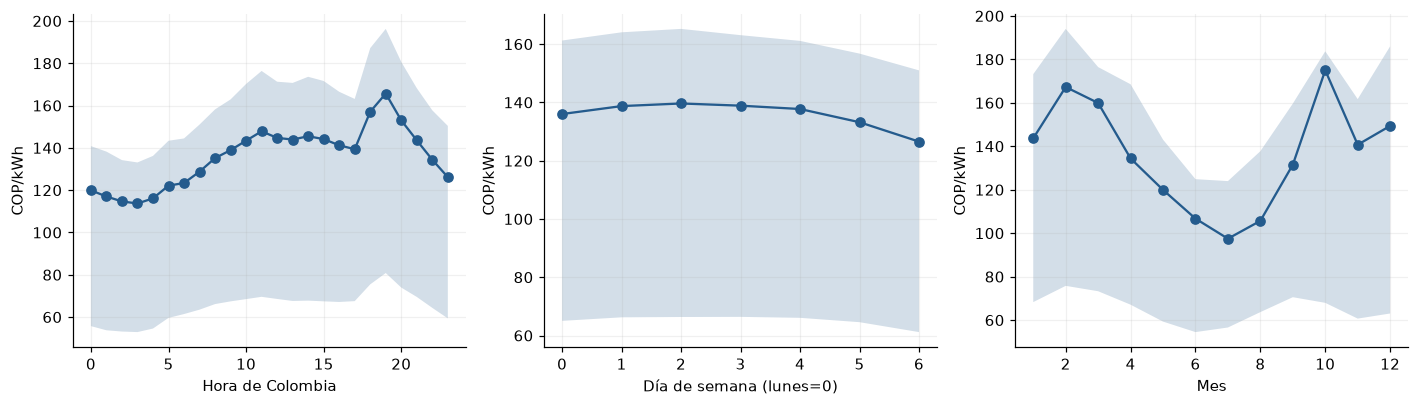

In [12]:
frame, daily = development_daily()
y = frame[TARGET]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, group, title in [(axes[0], frame.index.hour, 'Hora de Colombia'), (axes[1], frame.index.dayofweek, 'Día de semana (lunes=0)'), (axes[2], frame.index.month, 'Mes')]:
    grouped = y.groupby(group)
    mean = grouped.mean()
    lo = grouped.quantile(0.25)
    hi = grouped.quantile(0.75)
    ax.plot(mean.index, mean.values, marker='o')
    ax.fill_between(mean.index, lo, hi, alpha=0.2)
    ax.set(xlabel=title, ylabel='COP/kWh')
figure(fig, 'perfiles_estacionales')

**Interpretación.** El precio medio es mayor hacia las 19:00 y menor en la madrugada; el domingo presenta el menor nivel semanal. En el perfil mensual destacan octubre y febrero frente al mínimo de julio, con amplia dispersión dentro de cada grupo.

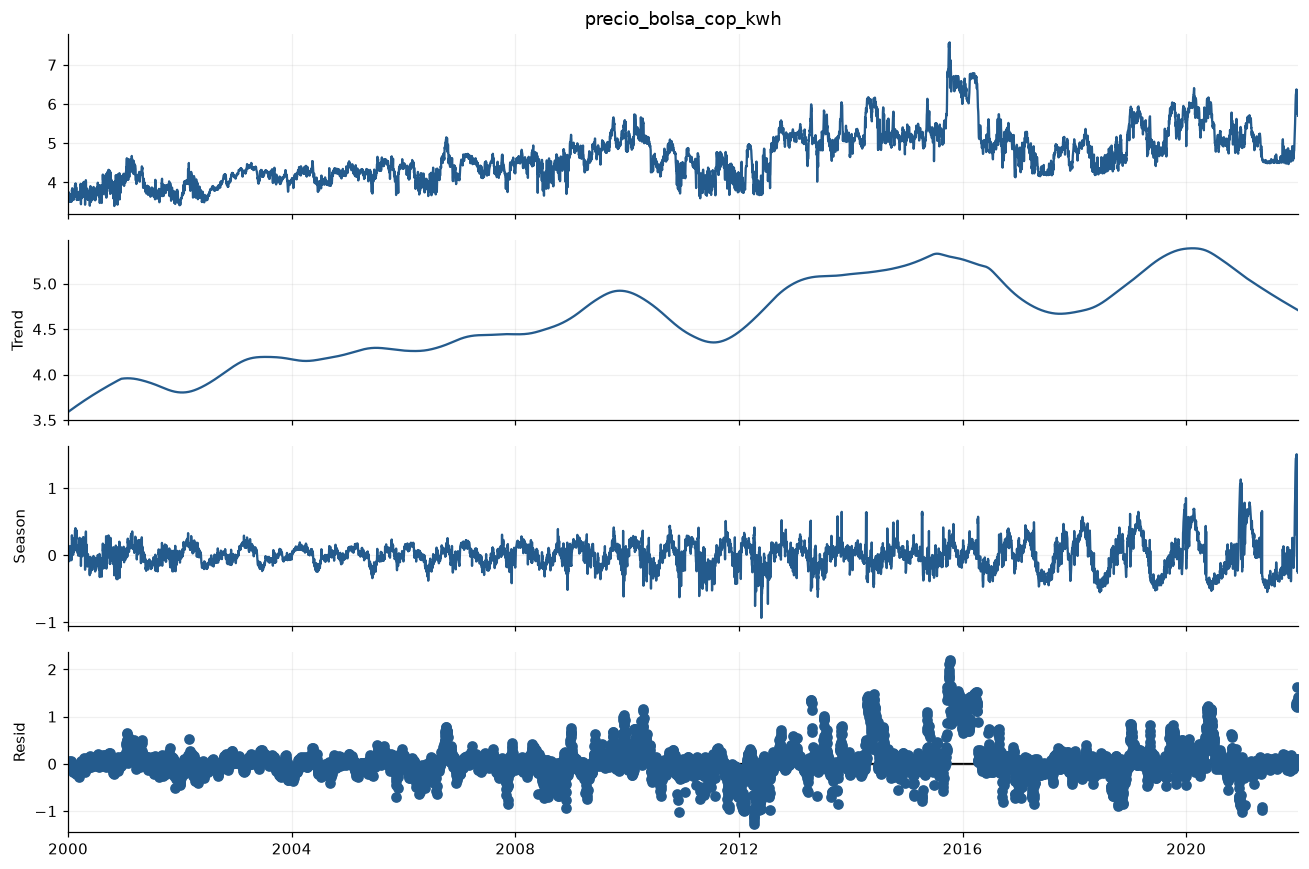

In [13]:
annual = STL(np.log1p(daily), period=365, robust=True).fit()
fig = annual.plot()
fig.set_size_inches(12, 8)
figure(fig, 'stl_diaria_anual')

**Interpretación.** La tendencia recoge cambios prolongados de nivel y la componente estacional varía de amplitud durante el periodo. Los residuos conservan picos marcados, especialmente en 2015–2016, por lo que tendencia y estacionalidad anual no explican todos los episodios extremos.

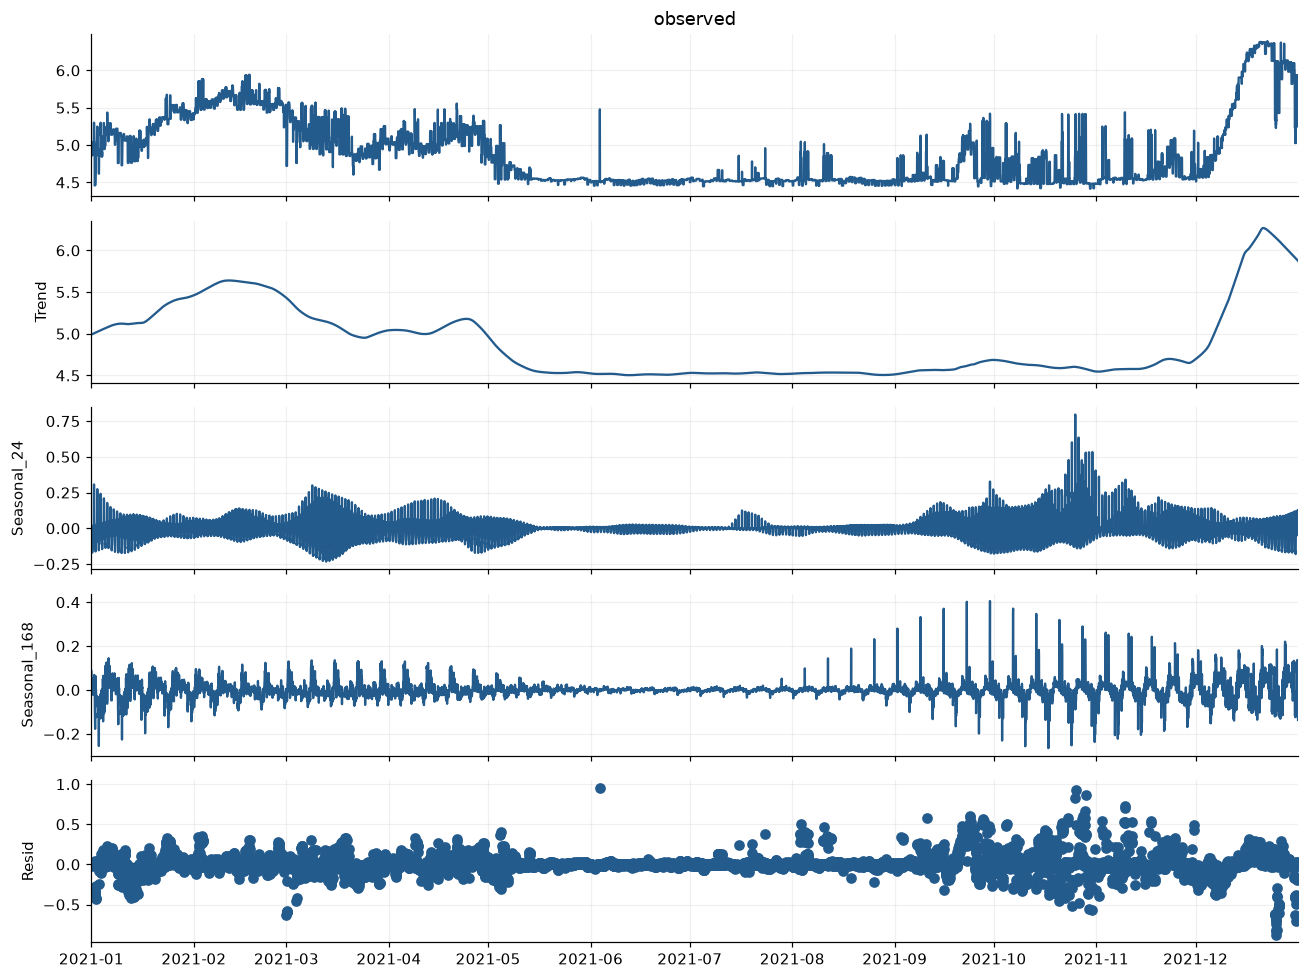

In [14]:
sub = np.log1p(y[y.index.year == 2021])
multiple = MSTL(sub, periods=(24, 168), stl_kwargs={'robust': True}).fit()
fig = multiple.plot()
fig.set_size_inches(12, 9)
figure(fig, 'mstl_horaria_2021')

**Interpretación.** En 2021, las componentes diaria y semanal pierden amplitud durante el tramo relativamente estable de mayo–septiembre y se intensifican en octubre–noviembre. El aumento de nivel de diciembre y los residuos persistentes indican variaciones que no quedan absorbidas por los ciclos diario y semanal.

In [15]:
freq, power = signal.welch(y.to_numpy(), fs=1, nperseg=24 * 365, detrend='linear')
valid = freq > 0
periods = 1 / freq[valid]
power = power[valid]
peaks = np.argsort(power)[-12:][::-1]
table(pd.DataFrame({'periodo_horas': periods[peaks], 'potencia': power[peaks]}), 'picos_espectrales_desarrollo')

,periodo_horas,potencia
0,8760,1.2361e+07
1,4380,8.1278e+06
2,2920,6.4343e+06
3,1752,3.0718e+06
4,2190,2.34e+06
5,1251.4,1.7579e+06
6,1095,1.3606e+06
7,1460,1.3501e+06
8,24,1.2871e+06
9,876,9.1981e+05


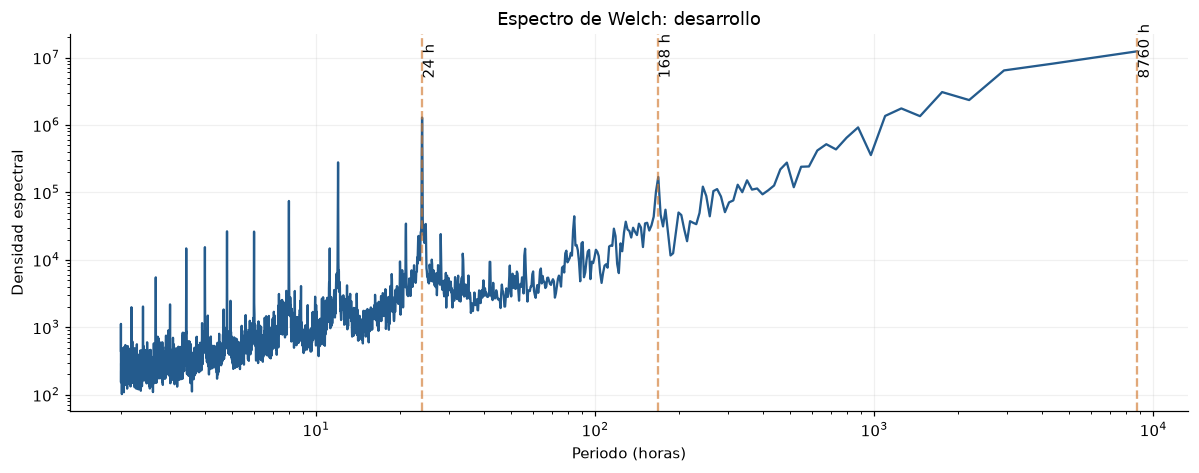

In [16]:
fig, ax = plt.subplots()
ax.loglog(periods, power)
for period in [24, 168, 24 * 365]:
    ax.axvline(period, color='#d17a32', alpha=0.65, ls='--')
    ax.text(period, ax.get_ylim()[1] / 4, str(period) + ' h', rotation=90)
ax.set(xlabel='Periodo (horas)', ylabel='Densidad espectral', title='Espectro de Welch: desarrollo')
figure(fig, 'espectro_desarrollo')

**Interpretación.** Aparecen picos en 24 y 168 horas, compatibles con los ciclos diario y semanal. La mayor potencia se concentra en periodos largos, incluido 8760 horas, señalando la importancia conjunta de estacionalidad y variaciones lentas del nivel.

In [17]:
decision('Calendario conocido al origen y rezagos diarios/semanales; el ciclo anual de 365 días aproxima años bisiestos.', 'Contexto candidato de una semana y salida de 24 horas; CNN local con acceso a rezagos estacionales o recurrencia/atención.', 'Comparar contra ingenuos diarios y semanales con los mismos orígenes. No escoger ventanas usando prueba.', 'Descomposiciones centradas son diagnóstico de train, no preprocesamiento causal listo para desplegar. Los perfiles no demuestran causalidad de hora o estación.')

### Implicaciones del análisis

- **Preprocesamiento:** Calendario conocido al origen y rezagos diarios/semanales; el ciclo anual de 365 días aproxima años bisiestos.
- **Arquitectura:** Contexto candidato de una semana y salida de 24 horas; CNN local con acceso a rezagos estacionales o recurrencia/atención.
- **Validación:** Comparar contra ingenuos diarios y semanales con los mismos orígenes. No escoger ventanas usando prueba.
- **Riesgos:** Descomposiciones centradas son diagnóstico de train, no preprocesamiento causal listo para desplegar. Los perfiles no demuestran causalidad de hora o estación.